# PharmaML — Cell Line Data Analysis (Zero to One Hundred)

One notebook, every stage of a cell-line pharmacology project, in the order
you would actually run it — from a raw drug-response screen to biomarkers
and a deep-learning response model:

| § | Stage | Toolkit |
|---|---|---|
| 1 | **Data entry** — GDSC-style response screen in, validated | `pharmaml.biology` |
| 2 | **QC audit** — missing values, duplicates, replicate collapse | `pharmaml.biology` |
| 3 | Normalization — LN_IC50 → pIC50, distributions | `pharmaml.biology` + `viz` |
| 4 | Response matrix — cell × compound potency landscape | `pharmaml.biology` |
| 5 | Sensitive vs resistant — quantile calls per drug | `pharmaml.biology` |
| 6 | Omics features — expression matrix, log2+z, variable genes | `pharmaml.biology` |
| 7 | **Biomarker discovery** — expression ↔ response with FDR | `pharmaml.biology` |
| 8 | Response model — predict pIC50 from expression (classical ML) | `pharmaml.ml` |
| 9 | **Deep learning** — `dnn` / `dnn_residual` in the leaderboard | `pharmaml.ml` |
| 10 | Recap | — |

The demo data is synthetic but structurally honest: EGFR expression is
planted to drive erlotinib/gefitinib sensitivity, so the biomarker call
in §7 genuinely recovers it. Point the loaders at your own GDSC/CCLE
exports (same columns) and every cell works unchanged.

In [1]:
import sys
import tempfile
from pathlib import Path

import pandas as pd

from pharmaml.biology import (
    load_response_table, audit_response_table, replicate_variability,
    collapse_replicates,
    ln_ic50_to_pic50, response_matrix, summarize_compounds,
    call_sensitive_resistant, normalize_expression, impute_expression,
    most_variable_genes, sensitivity_associations, top_biomarkers,
    direction_of_association,
)

WORK = Path(tempfile.mkdtemp(prefix="cellline_"))

from pharmaml import __version__

print(f"pharmaml {__version__}")
# The shipped demo inventory: the screen and the expression matrix load
# from examples/data/ instead of being fabricated inline.
DATA_DIR = Path("data")
pd.set_option("display.width", 120)

print("python:", sys.version.split()[0], "| working dir:", WORK)


pharmaml 1.2.74
python: 3.12.15 | working dir: /tmp/cellline_xlbnoigo


## 1 · Data entry — a GDSC-style response screen

The screen arrives (or is exported) in **long format**: one row per
(cell line, compound) pair with a potency metric — here `LN_IC50`,
the natural log of the IC50 in µM, exactly as GDSC ships it.
`load_response_table` validates the columns, auto-detects metric
columns and refuses mistyped inputs with a message that names the
offending column.

The synthetic panel: **23 cell lines** across 11 tissues, **8
compounds**, with one deliberate duplicate pair and one missing value
(§2 needs something honest to audit). It ships as
`examples/data/cellline_screen.csv` (185 rows, seed 42; regenerate
deterministically via `scratch/build_example_data.py`).

In [2]:
# --- DEMO DATA (shipped) --------------------------------------------------
# The GDSC-style screen shipped as examples/data/cellline_screen.csv:
# 23 cell lines x 8 compounds with the planted EGFR signal, plus one
# duplicate pair (assay repeat) and one missing value for §2 to audit.
# (In your project: point screen_path at your own GDSC/CCLE export.)
screen_path = DATA_DIR / "cellline_screen.csv"   # <- replace with your own export

screen_frame = pd.read_csv(screen_path)
print(f"{len(screen_frame)} rows loaded <- {screen_path}")


185 rows loaded <- data/cellline_screen.csv


In [3]:
# --- THE ACTUAL IMPORT (works unchanged for your GDSC/CCLE export) --------
screen = load_response_table(screen_path, tissue_column="tissue")
print(screen.summary())

screen        : 23 cell line(s) x 8 compound(s) -> 184 (cell, compound) pair(s)
rows          : 185 (1 duplicate row(s))
tissue        : 11 value(s) in 'tissue': CNS, bone, breast, cervix, colon, haematopoietic, liver, lung (+3 more)
metrics       : LN_IC50
  LN_IC50      : 184/185 value(s) present (1 missing)
dup. pairs    : 1: (MCF-7 + crizotinib)


## 2 · QC audit — find what the screen is hiding

`audit_response_table` returns one row per issue class: missing metric
values, duplicated (cell line, compound) pairs, cell lines mapping to
more than one tissue, and compounds tested on too few lines. Then
`collapse_replicates` resolves duplicates the GDSC way — median per
pair — leaving a clean screen behind.

In [4]:
audit = audit_response_table(screen)
audit

,issue,detail,count
0,missing metric values,metric 'LN_IC50',1
1,duplicate pairs,MCF-7 / crizotinib,2


In [5]:
clean = collapse_replicates(screen)
print(f"{len(screen.frame)} rows -> {len(clean.frame)} rows after replicate collapse")
audit_response_table(clean)

185 rows -> 184 rows after replicate collapse


,issue,detail,count
0,missing metric values,metric 'LN_IC50',1


### Replicate variability — how noisy was that median?

`collapse_replicates` resolves a duplicated pair by the median, and the
median is silent about spread: replicates `[1.0, 3.0]` and `[1.9, 2.1]`
both collapse to **2.0**. `replicate_variability` reports what the
collapse is about to discard — replicate count, median, mean, std,
spread and the coefficient of variation (`cv_pct` = std / |mean| × 100;
NaN for single observations or zero means, never a fabricated inf) —
and `collapse_replicates(screen, add_cv=True)` keeps a
`{metric}_replicate_cv_pct` companion column next to every collapsed
median so the noise travels with the answer. The CLI twin is
`pharmaml biology response-audit --replicate-cv`.


In [6]:
# The median collapse discards noise by construction: replicates [1.0, 3.0]
# and [1.9, 2.1] both collapse to the SAME median 2.0 -- the CV keeps the
# difference visible BEFORE the collapse (CV% = std / |mean| * 100).
cv_demo = pd.DataFrame({
    "cell_line": ["A", "A", "B", "B"],
    "compound": ["demo", "demo", "demo", "demo"],
    "LN_IC50": [1.0, 3.0, 1.9, 2.1],
})
demo_screen = load_response_table(cv_demo, metrics=["LN_IC50"])
print(replicate_variability(demo_screen).to_string(index=False))
print()

# The shipped screen: one duplicated pair -- MCF-7 x crizotinib.
variability = replicate_variability(screen)
print(variability.to_string(index=False))
print()

# add_cv=True keeps the noise NEXT TO the answer: a companion
# {metric}_replicate_cv_pct column rides along with the collapsed median
# (NaN for singleton pairs -- their spread is undefined, not zero).
clean_cv = collapse_replicates(screen, add_cv=True)
clean_cv.frame[clean_cv.frame["compound"] == "crizotinib"][
    ["cell_line", "compound", "LN_IC50", "LN_IC50_replicate_cv_pct"]
]


cell_line compound  metric  n_replicates  median  mean      std  spread    cv_pct
        A     demo LN_IC50             2     2.0   2.0 1.414214     2.0 70.710678
        B     demo LN_IC50             2     2.0   2.0 0.141421     0.2  7.071068

cell_line   compound  metric  n_replicates   median     mean  std  spread  cv_pct
    MCF-7 crizotinib LN_IC50             2 3.712163 3.712163  0.0     0.0     0.0



,cell_line,compound,LN_IC50,LN_IC50_replicate_cv_pct
5,MCF-7,crizotinib,3.712163,0.0
13,T-47D,crizotinib,3.871254,NaN
21,BT-549,crizotinib,3.574715,NaN
29,A549,crizotinib,2.340996,NaN
37,H1299,crizotinib,2.785670,NaN
45,H1975,crizotinib,3.134123,NaN
53,HepG2,crizotinib,3.594362,NaN
61,Huh7,crizotinib,3.539864,NaN
69,K-562,crizotinib,3.622383,NaN
77,Jurkat,crizotinib,3.788399,NaN


Same median, ten-fold different noise: pair A collapses to 2.0 from
replicates that disagree by 70.7 %, pair B from replicates that agree to
7.1 % — the median alone cannot tell them apart, `cv_pct` can. The
shipped screen's single duplicate (`MCF-7` × crizotinib, two
byte-identical rows) collapses with CV 0.0 — the median is exact — while
every singleton pair carries NaN: its spread is undefined, not zero.
Real GDSC exports carry genuine replicate noise; check `cv_pct` before
trusting a collapsed median.


## 3 · Normalization — LN_IC50 → pIC50

GDSC's `LN_IC50` is ln(IC50 in µM); pharmacology prefers pIC50 =
−log10(IC50 in M) — bigger is *more* potent. `ln_ic50_to_pic50` does the
exact conversion (pIC50 = 6 − LN_IC50 / ln 10) and the histogram grid
shows every compound's potency distribution across the panel.

In [7]:
pic50_frame = clean.frame.copy()
pic50_frame["pIC50"] = ln_ic50_to_pic50(pic50_frame["LN_IC50"])
screen_p = load_response_table(pic50_frame, tissue_column="tissue", metrics=["pIC50"])

# Hand-check: 1 µM IC50 (LN_IC50 = 0) must be exactly pIC50 6.
print("ln_ic50_to_pic50(0.0) =", round(float(ln_ic50_to_pic50(0.0)), 6))

pic50_frame[["cell_line", "compound", "LN_IC50", "pIC50"]].head(8)

ln_ic50_to_pic50(0.0) = 6.0


,cell_line,compound,LN_IC50,pIC50
0,MCF-7,erlotinib,3.208520,4.606558
1,MCF-7,gefitinib,3.306217,4.564128
2,MCF-7,everolimus,2.386616,4.963506
3,MCF-7,dasatinib,2.895816,4.742363
4,MCF-7,sorafenib,3.965780,4.277684
5,MCF-7,crizotinib,3.712163,4.387828
6,MCF-7,paclitaxel,2.177548,5.054303
7,MCF-7,cisplatin,3.285497,4.573127


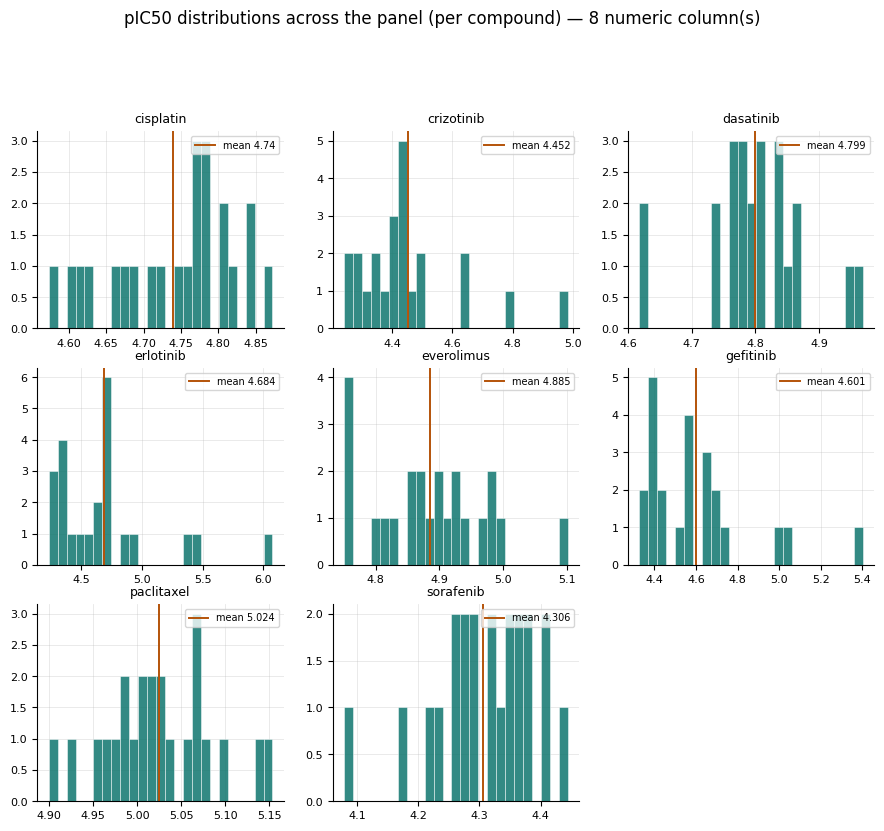

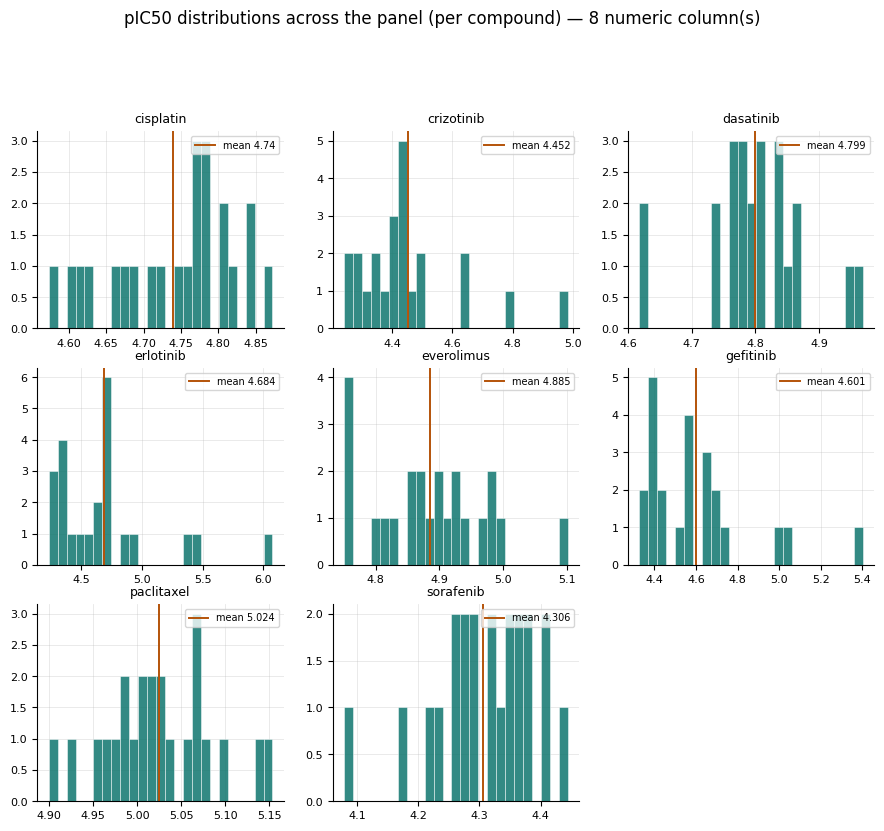

In [8]:
from pharmaml.viz import plot_descriptor_distributions

fig_dist = plot_descriptor_distributions(
    response_matrix(screen_p, "pIC50"),
    title="pIC50 distributions across the panel (per compound)",
)
fig_dist

## 4 · Response matrix — the cell × compound potency landscape

`response_matrix` pivots the long table into the classic screening
matrix (cell lines × compounds, NaN where untested);
`summarize_compounds` ranks the panel per compound — median potency,
spread across the panel, and the most sensitive line.

In [9]:
matrix = response_matrix(screen_p, "pIC50")
print(f"matrix: {matrix.shape[0]} cell lines x {matrix.shape[1]} compounds")
matrix.round(2)

matrix: 23 cell lines x 8 compounds


compound,cisplatin,crizotinib,dasatinib,erlotinib,everolimus,gefitinib,paclitaxel,sorafenib
cell_line,,,,,,,,
A549,4.78,4.98,4.76,6.08,4.87,5.41,5.03,4.26
BT-549,4.67,4.45,4.84,4.68,4.89,4.55,5.07,4.29
DLD-1,4.63,4.34,4.77,4.54,4.86,4.57,4.97,NaN
DU-145,4.78,4.42,4.79,4.69,4.91,4.67,4.92,4.17
H1299,4.73,4.79,4.85,5.39,4.75,5.02,5.03,4.23
H1975,4.84,4.64,4.81,5.46,4.81,5.04,5.02,4.34
HCT-116,4.71,4.40,4.86,4.71,4.89,4.71,5.14,4.33
HT-29,4.62,4.44,4.78,4.72,4.98,4.66,5.00,4.35
HeLa,4.74,4.29,4.87,4.32,4.76,4.38,5.03,4.38


In [10]:
summary = summarize_compounds(screen_p, "pIC50")
summary.round(3).sort_values("median", ascending=False)

,n_cell_lines,median,min,max,std,sensitive_spread,most_sensitive_cell_line
compound,,,,,,,
paclitaxel,23,5.018,4.900,5.154,0.062,0.254,Jurkat
everolimus,23,4.887,4.751,5.101,0.090,0.350,OVCAR-3
dasatinib,23,4.793,4.618,4.970,0.080,0.352,MIA PaCa-2
cisplatin,23,4.768,4.573,4.872,0.082,0.299,MCF-7
erlotinib,23,4.631,4.229,6.077,0.445,1.848,T-47D
gefitinib,23,4.564,4.328,5.405,0.261,1.077,T-47D
crizotinib,23,4.427,4.241,4.983,0.174,0.742,PC-3
sorafenib,23,4.316,4.078,4.445,0.085,0.366,U-251


## 5 · Sensitive vs resistant — quantile calls

For one drug, `call_sensitive_resistant` labels each cell line by
response quantiles (default 25th/75th). pIC50 is
`lower_is_sensitive=False` — *high* pIC50 means *low* IC50 means
sensitive.

In [11]:
erlo = matrix["erlotinib"].dropna()
labels = call_sensitive_resistant(erlo, lower_is_sensitive=False)
print(labels.value_counts().to_string())
labels[labels != "intermediate"]

intermediate    11
sensitive        6
resistant        6


cell_line
A549          sensitive
H1299         sensitive
H1975         sensitive
HeLa          resistant
Jurkat        resistant
MIA PaCa-2    resistant
OVCAR-3       resistant
PANC-1        sensitive
PC-3          resistant
Saos-2        sensitive
T-47D         resistant
U-87 MG       sensitive
dtype: object

## 6 · Omics features — expression in, genes selected

The expression matrix: **rows = cell lines, columns = genes** — the same
orientation as every `X` in `pharmaml.ml`, so it feeds models directly.
`normalize_expression` does log2(x+1) + per-gene z-score;
`most_variable_genes` picks the MAD-highest genes (the ones that carry
panel structure — 300 random genes are planted, plus EGFR with its
lung-line signal, and another gene carrying a breast signature so
selection isn't a one-gene show).

In [12]:
# --- DEMO EXPRESSION MATRIX (shipped) --------------------------------------
# examples/data/cellline_expression.csv: rows = cell lines, columns = genes
# (298 random genes + EGFR carrying the lung-line signal + KRT8 carrying a
# breast signature; same seed-42 chain that built the screen, so the
# planted biomarker agrees with it).
expression = pd.read_csv(DATA_DIR / "cellline_expression.csv", index_col="cell_line")

expr_norm = normalize_expression(expression)
top_genes = most_variable_genes(expr_norm, n=40)
print(f"expression: {expr_norm.shape[0]} cell lines x {expr_norm.shape[1]} genes (normalized)")
print("top variable genes (first 6):", top_genes[:6])
print("EGFR rank:", top_genes.index("EGFR") + 1 if "EGFR" in top_genes else "not in top 40")


expression: 23 cell lines x 300 genes (normalized)
top variable genes (first 6): ['GENE_248', 'GENE_190', 'GENE_113', 'GENE_028', 'GENE_067', 'GENE_243']
EGFR rank: not in top 40


## 7 · Biomarker discovery — which genes explain sensitivity?

`sensitivity_associations` correlates **every gene** against one drug's
response vector across the panel (Spearman by default), then adjusts the
p-values for 300 simultaneous tests with Benjamini–Hochberg FDR. This is
the classic "omics → biomarker" step — and it genuinely recovers the
planted EGFR → erlotinib association here.

In [13]:
associations = sensitivity_associations(
    expr_norm, erlo, method="spearman", fdr_alpha=0.05
)
hits = top_biomarkers(associations, n=8)
hits

only 1 significant association(s) -- returning the top 8 of all 300 association(s) ranked by |rho|


,gene,rho,p_value,fdr,significant
0,EGFR,0.978261,7.877399e-16,2.363220e-13,True
1,GENE_009,0.591897,2.927362e-03,4.391043e-01,False
2,GENE_090,0.556324,5.837466e-03,4.980743e-01,False
3,GENE_148,-0.543478,7.356176e-03,4.980743e-01,False
4,GENE_186,-0.536561,8.301238e-03,4.980743e-01,False
5,GENE_273,-0.514822,1.194765e-02,5.203041e-01,False
6,GENE_251,-0.513834,1.214043e-02,5.203041e-01,False
7,GENE_184,0.499012,1.535153e-02,5.517441e-01,False


In [14]:
best = associations.loc[associations["gene"] == "EGFR"].iloc[0]
print(f"EGFR vs erlotinib: rho={best['rho']:+.3f}  p={best['p_value']:.2e}  "
      f"FDR={best['fdr']:.2e}  significant={best['significant']}")
print(direction_of_association(best["rho"], lower_is_sensitive=False))

# Same story, weaker coefficient, second EGFR inhibitor:
gefi = matrix["gefitinib"].dropna().loc[erlo.index]
assoc_gefi = sensitivity_associations(expr_norm, gefi.reindex(erlo.index))
best_gefi = assoc_gefi.loc[assoc_gefi["gene"] == "EGFR"].iloc[0]
print(f"\nEGFR vs gefitinib: rho={best_gefi['rho']:+.3f}  "
      f"FDR={best_gefi['fdr']:.2e}  (same target, weaker planted effect)")

EGFR vs erlotinib: rho=+0.978  p=7.88e-16  FDR=2.36e-13  significant=True
expression high -> more sensitive



EGFR vs gefitinib: rho=+0.924  FDR=9.59e-08  (same target, weaker planted effect)


## 8 · Response model — predict pIC50 from expression

Classical ML on the top-40 variable genes: stratified split, elastic net
vs random forest, honest held-out metrics. The signal is EGFR, so the
models have something real to learn.

In [15]:
from pharmaml.ml import make_train_test_split, train_model, evaluate_model

X = expr_norm.loc[erlo.index, top_genes]
y = erlo

Xtr, Xte, ytr, yte = make_train_test_split(X, y, test_size=0.25, random_state=42)

en = train_model("elastic_net", "regression", Xtr, ytr, tune=True)
en_report = evaluate_model(en.model, Xte, yte, "regression", keep_predictions=True)
print(f"elastic_net  rmse={en_report.rmse:.3f}  r2={en_report.r2:.3f}")

rf = train_model("random_forest", "regression", Xtr, ytr, tune=False)
rf_report = evaluate_model(rf.model, Xte, yte, "regression", keep_predictions=True)
print(f"random_forest rmse={rf_report.rmse:.3f}  r2={rf_report.r2:.3f}")

elastic_net  rmse=0.611  r2=0.098
random_forest rmse=0.638  r2=0.018


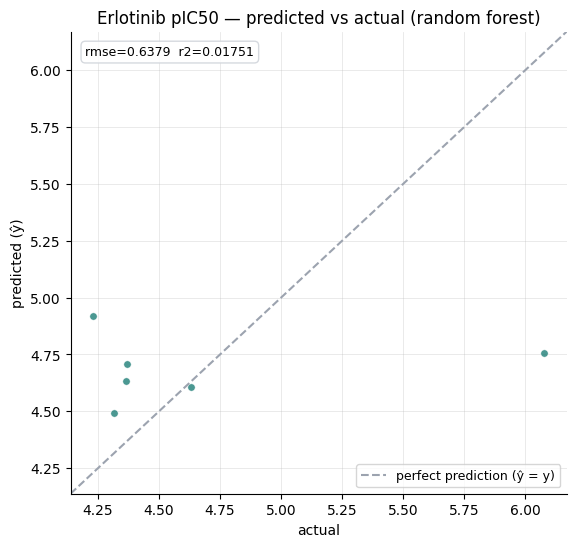

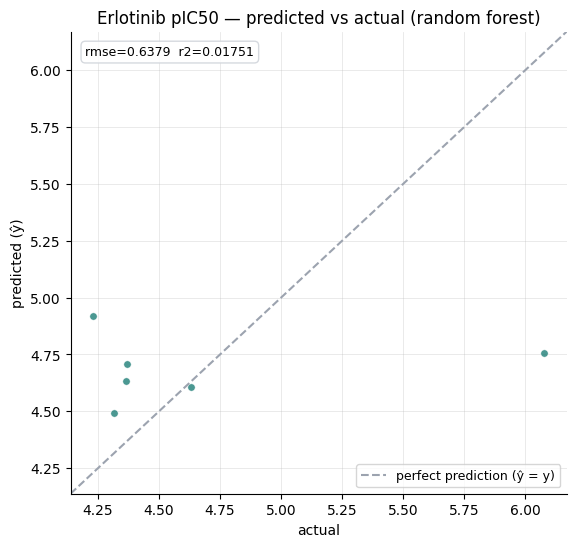

In [16]:
from pharmaml.viz import plot_predicted_vs_actual

fig_parity = plot_predicted_vs_actual(
    yte, rf_report.predictions,
    metrics={"rmse": rf_report.rmse, "r2": rf_report.r2},
    title="Erlotinib pIC50 — predicted vs actual (random forest)",
)
fig_parity

## 9 · Deep learning — `dnn` and `dnn_residual` join the leaderboard

The registry's two PyTorch families (deep feed-forward nets with
early stopping, and residual nets with learned skip projections) plug
into the *same* `compare_models` call as every classical model —
cross-validated, tuned and scored identically. They need
`pip install 'pharmaml[deep]'`; without torch they simply show as
unavailable instead of breaking anything.

In [17]:
from pharmaml.ml import compare_models, list_models

deep_rows = [m for m in list_models(task="regression") if m["name"] in ("dnn", "dnn_residual")]
for m in deep_rows:
    print(f"{m['name']:<14} available={m['available']}  {m['notes']}")

dnn            available=True  deep feed-forward network (PyTorch, batchnorm=True available) — needs `pip install 'pharmaml[deep]'`
dnn_residual   available=True  residual deep network (PyTorch, batchnorm=True available) — needs `pip install 'pharmaml[deep]'`


In [18]:
leaderboard = compare_models(
    X, y, task="regression",
    models=["elastic_net", "random_forest", "ann", "dnn", "dnn_residual"],
    cv=3,
)
leaderboard

,model,neg_root_mean_squared_error_mean,neg_root_mean_squared_error_std,fit_time_s,folds
0,dnn,-0.468799,0.172733,1.480591,3
1,elastic_net,-0.492122,0.184626,0.003554,3
2,dnn_residual,-0.495739,0.168999,0.066360,3
3,random_forest,-0.501232,0.167004,0.063103,3
4,ann,-2.014623,0.504448,0.018759,3


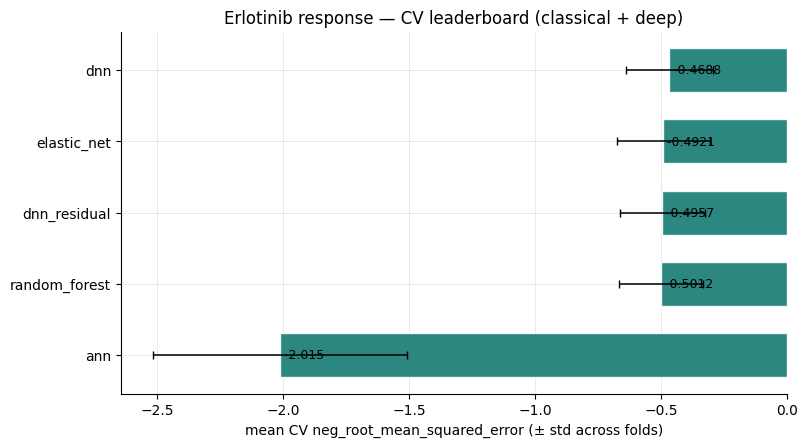

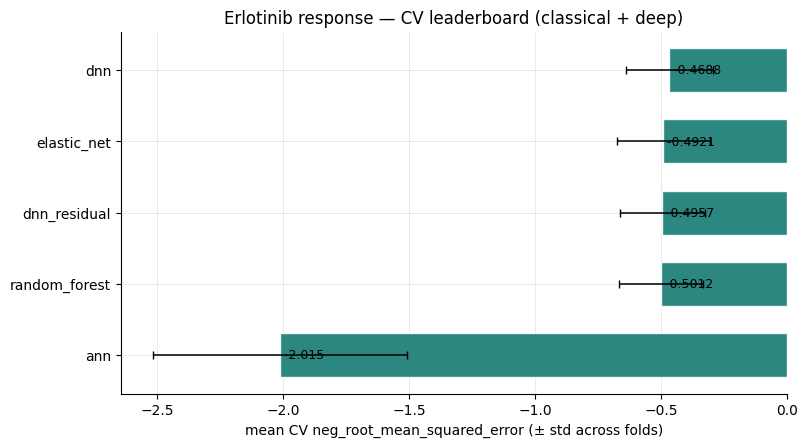

In [19]:
from pharmaml.viz import plot_model_comparison

fig_board = plot_model_comparison(leaderboard, title="Erlotinib response — CV leaderboard (classical + deep)")
fig_board

## 10 · Recap

| Stage | One-liner |
|---|---|
| Load screen | `load_response_table("screen.csv", tissue_column="tissue")` |
| Audit | `audit_response_table(screen)` |
| Collapse replicates | `collapse_replicates(screen)` |
| Replicate variability | `replicate_variability(screen)` |
| Normalize | `ln_ic50_to_pic50(frame["LN_IC50"])` |
| Response matrix | `response_matrix(screen, "pIC50")` |
| Rank compounds | `summarize_compounds(screen, "pIC50")` |
| Call sensitivity | `call_sensitive_resistant(series, lower_is_sensitive=False)` |
| Normalize omics | `normalize_expression(expression)` |
| Select genes | `most_variable_genes(expr, n=40)` |
| Find biomarkers | `sensitivity_associations(expr, response)` |
| Classical model | `train_model("elastic_net", "regression", Xtr, ytr)` |
| Deep learning | `compare_models(..., models=[..., "dnn", "dnn_residual"])` |

Next steps with real data: point §1 at your GDSC/CCLE export, §6 at a
CCLE expression matrix, and re-run — every stage is the same call.